The goal of this notebook is to explore anomaly detection using an autoencoder trained to reconstruct handwritten digits, excluding the digit 5 from training. We then test whether unseen 5s tend to have higher reconstruction errors and can therefore be identified as anomalies.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, UpSampling2D, Conv2DTranspose, Dropout, Flatten, Dense, Reshape, BatchNormalization, Activation
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.losses import MeanSquaredError
from sklearn.metrics import roc_curve, auc, confusion_matrix
import seaborn as sns
from sklearn.model_selection import train_test_split

In [2]:
# Load MNIST dataset
(x_train, y_train), (x_test, y_test) = mnist.load_data()

In [3]:
# Normalize the dataset
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0
x_train = np.expand_dims(x_train, axis=-1)  # Add channel dimension
x_test = np.expand_dims(x_test, axis=-1)
# merge test and training
x_train = np.concatenate((x_train, x_test))
y_train = np.concatenate((y_train, y_test))
del x_test, y_test

In [4]:
print(x_train.shape, y_train.shape)

(70000, 28, 28, 1) (70000,)


In [5]:
# Extract normal (background) digits (excluding digit 5)
normal_digits = np.where(y_train != 5)[0] #numpy mask
anomaly_digits = np.where(y_train == 5)[0]
x_normal = x_train[normal_digits]
x_anomalies = x_train[anomaly_digits]

In [6]:
# Split the normal digits into train, validation, and test sets (50%, 25%, 25%)
x_train_normal, x_temp  = train_test_split(x_normal, test_size=0.5, random_state=42)
x_val_normal, x_test_normal = train_test_split(x_temp, test_size=0.5, random_state=42)

In [7]:
# Combine test set with anomalies (label 0 for background, 1 for anomalies)
x_test = np.concatenate([x_test_normal, x_anomalies], axis=0)
y_test = np.concatenate([np.zeros(len(x_test_normal)), np.ones(len(x_anomalies))], axis=0)
# shuffle them if you want. Not really needed

In [8]:
print(x_train_normal.shape, x_val_normal.shape, x_test_normal.shape)
print(x_test.shape, y_test.shape)

(31843, 28, 28, 1) (15922, 28, 28, 1) (15922, 28, 28, 1)
(22235, 28, 28, 1) (22235,)


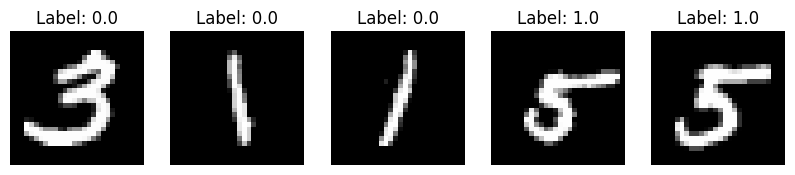

In [9]:
# Visualize some digits from the dataset
fig, axes = plt.subplots(1, 5, figsize=(10, 3))
digits = [1,2,3,-1,-2]
for i, ax in enumerate(axes):
    ax.imshow(x_test[digits[i]].reshape(28, 28), cmap='gray')
    ax.set_title(f"Label: {y_test[digits[i]]}")
    ax.axis('off')
plt.show()

In [10]:
def build_autoencoder(input_shape):
    input_img = Input(shape=input_shape)

    # ----- Encoder -----
    x = Conv2D(1, (3, 3), activation='relu', padding='same')(input_img) # 1 filter 3*3, learns local features, "same" padding preserves the spatial dimensions: (28, 28, 1)
    x = MaxPooling2D((2, 2), padding='same')(x) # reduce spatial dimensions
    # -> output shape (14, 14, 1)

    # bottleneck
    x = Flatten()(x) # Convert the feature map in a vector of 196 values (dimension 14*14=196)
    x = Dense(3, activation ='relu')(x) # Encode the image using three learned latent values
    x = Dense(14 * 14 * 1, activation ='relu')(x) #  Expand the latent vector into 196 values
    x = Reshape((14,14,1))(x) # Recreat a map

    # ----- Decoder -----
    x = UpSampling2D((2, 2))(x) # (14*14*1->28*28*1)
    decoded = Conv2D(1, (3, 3), activation='sigmoid', padding='same')(x) # Reconstruct the image, why sigmoid?
    # -> output shape (28, 28, 1)

    autoencoder = Model(input_img, decoded)
    return autoencoder

In [11]:
# Build the autoencoder model
input_shape = (28, 28, 1)
autoencoder = build_autoencoder(input_shape)
autoencoder.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 28, 28, 1)      │            10 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 196)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 3)              │           591 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 196)            │           784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 14, 14, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d (UpSampling2D)    │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 28, 28, 1)      │            10 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,395 (5.45 KB)

 Trainable params: 1,395 (5.45 KB)

 Non-trainable params: 0 (0.00 B)

In [12]:
# Compile the model
autoencoder.compile(optimizer='adam', loss=MeanSquaredError()) # MSE mean quadratic difference between original pixel and reconstructed

In [13]:
# Early stopping to avoid overfitting
early_stopping = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

In [14]:
# Train the autoencoder on the training data
history = autoencoder.fit(x_train_normal, x_train_normal,
                          epochs=20,
                          batch_size=64,
                          shuffle=True,
                          validation_data=(x_val_normal, x_val_normal),
                          callbacks=[early_stopping])

Epoch 1/20
498/498 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - loss: 0.1302 - val_loss: 0.0677
Epoch 2/20
498/498 ━━━━━━━━━━━━━━━━━━━━ 0s 941us/step - loss: 0.0630 - val_loss: 0.0608
Epoch 3/20
498/498 ━━━━━━━━━━━━━━━━━━━━ 0s 943us/step - loss: 0.0594 - val_loss: 0.0586
Epoch 4/20
498/498 ━━━━━━━━━━━━━━━━━━━━ 0s 965us/step - loss: 0.0582 - val_loss: 0.0576
Epoch 5/20
498/498 ━━━━━━━━━━━━━━━━━━━━ 0s 938us/step - loss: 0.0573 - val_loss: 0.0566
Epoch 6/20
498/498 ━━━━━━━━━━━━━━━━━━━━ 0s 944us/step - loss: 0.0563 - val_loss: 0.0557
Epoch 7/20
498/498 ━━━━━━━━━━━━━━━━━━━━ 1s 983us/step - loss: 0.0555 - val_loss: 0.0549
Epoch 8/20
498/498 ━━━━━━━━━━━━━━━━━━━━ 0s 928us/step - loss: 0.0548 - val_loss: 0.0544
Epoch 9/20
498/498 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.0543 - val_loss: 0.0540
Epoch 10/20
498/498 ━━━━━━━━━━━━━━━━━━━━ 0s 932us/step - loss: 0.0539 - val_loss: 0.0536
Epoch 11/20
498/498 ━━━━━━━━━━━━━━━━━━━━ 1s 994us/step - loss: 0.0536 - val_loss: 0.0534
Epoch 12/20
498/498 ━━━━━━━━━━━━━━

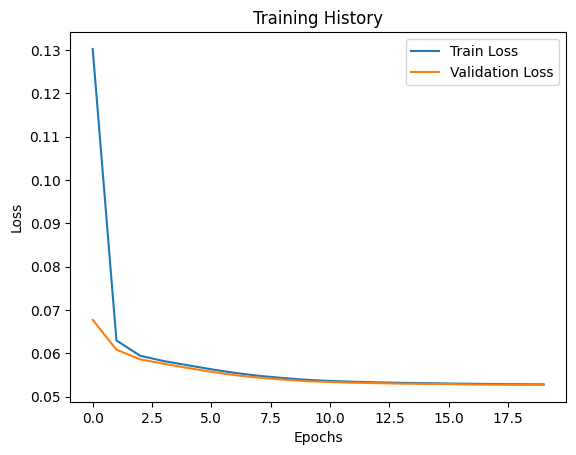

In [15]:
# Plot the training history
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Training History')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [16]:
# Calculate MSE for the validation dataset
x_out_test = autoencoder.predict(x_test)
mse_test= np.mean(np.square(x_test - x_out_test), axis=(1, 2, 3)) # Higher MSE indicates a more anomalous image according to this score.

695/695 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step  


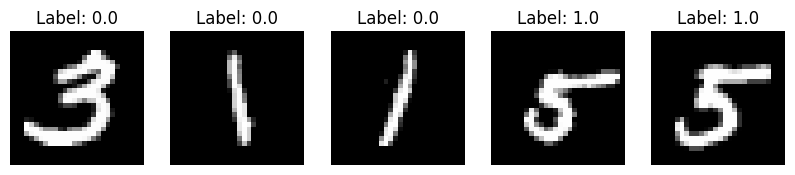

In [17]:
# Visualize some digits from the dataset
fig, axes = plt.subplots(1, 5, figsize=(10, 3))
digits = [1,2,3,-1,-2]
for i, ax in enumerate(axes):
    ax.imshow(x_test[digits[i]].reshape(28, 28), cmap='gray')
    ax.set_title(f"Label: {y_test[digits[i]]}")
    ax.axis('off')
plt.show()

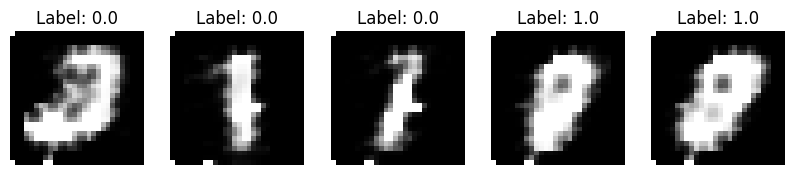

In [18]:
# Visualize some digits from the output dataset
fig, axes = plt.subplots(1, 5, figsize=(10, 3))
digits = [1,2,3,-1,-2]
for i, ax in enumerate(axes):
    ax.imshow(x_out_test[digits[i]].reshape(28, 28), cmap='gray')
    ax.set_title(f"Label: {y_test[digits[i]]}")
    ax.axis('off')
plt.show()

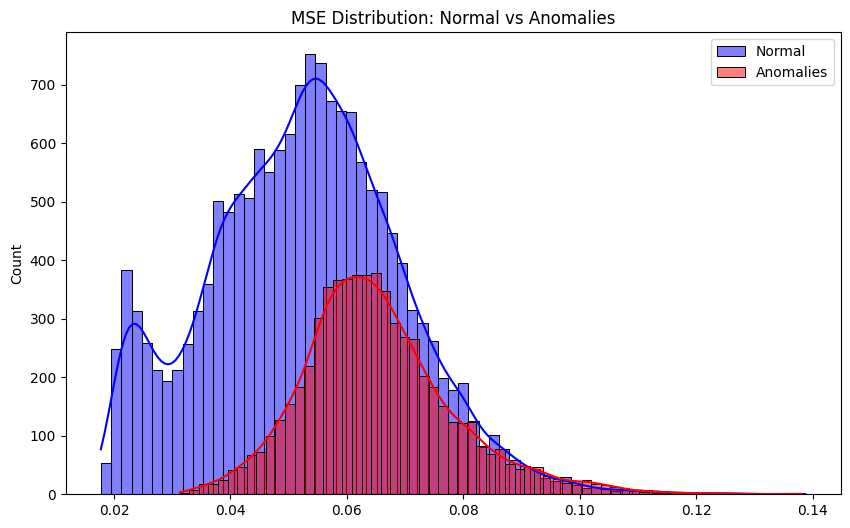

In [19]:
# Plot the distribution of MSE for normal vs anomalies
plt.figure(figsize=(10,6))
sns.histplot(mse_test[y_test == 0], label='Normal', color='blue', kde=True)
sns.histplot(mse_test[y_test == 1], label='Anomalies', color='red', kde=True)
plt.title('MSE Distribution: Normal vs Anomalies')
plt.legend()
plt.show()

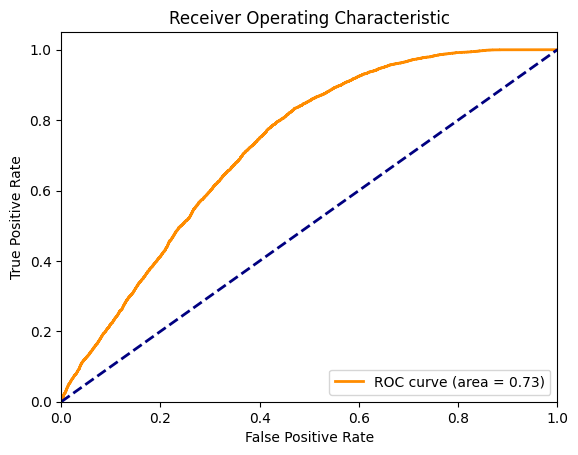

In [20]:
# ROC curve
fpr, tpr, thresholds = roc_curve(y_test, mse_test)
roc_auc = auc(fpr, tpr)

plt.figure()
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()

# If you want to try a VAE

You need to define a custom loss, sum of the reco loss (here MSE) and the KLD term

You need to modify the encoder so that it has 2k outout for k latent dimensions

You need to sample the z


In [21]:
# build the encoder
encoder_inputs = Input(shape=(28, 28, 1))
latent_dim = ...

...

# Latent variables
z_mean = Dense(latent_dim, name="z_mean")(x)
z_log_var = Dense(latent_dim, name="z_log_var")(x)

# Sampling layer
def sampling(args):
    z_mean, z_log_var = args
    epsilon = K.random_normal(shape=(K.shape(z_mean)[0], latent_dim), mean=0., stddev=1.)
    return z_mean + K.exp(0.5 * z_log_var) * epsilon

z = Lambda(sampling, output_shape=(latent_dim,), name="z")([z_mean, z_log_var])

encoder = Model(encoder_inputs, [z_mean, z_log_var, z], name="encoder")
encoder.summary()


ValueError: Received an invalid value for `units`, expected a positive integer. Received: units=Ellipsis

In [ ]:
# build the decoder
latent_inputs = Input(shape=(latent_dim,))
x = .... (latent_inputs)
decoder_outputs = ... (x)

decoder = Model(latent_inputs, decoder_outputs, name="decoder")
decoder.summary()


In [ ]:
# Build  the VAE
z_mean, z_log_var, z = encoder(encoder_inputs)
reconstructed = decoder(z)
vae = models.Model(encoder_inputs, reconstructed, name="vae")

In [ ]:
def vae_loss_mse(inputs, outputs, z_mean, z_log_var):
    # Reconstruction loss (MSE)
    reconstruction_loss = tf.keras.losses.mse(
        K.flatten(inputs),
        K.flatten(outputs)
    )
    reconstruction_loss *= 28 * 28  # scale up to image size

    # KL divergence loss
    kl_loss = 1 + z_log_var - K.square(z_mean) - K.exp(z_log_var)
    kl_loss = K.sum(kl_loss, axis=-1)
    kl_loss *= -0.5

    # Total loss
    total_loss = K.mean(reconstruction_loss + kl_loss)
    return total_loss

In [ ]:
vae.compile(
    optimizer='adam',
    loss=lambda x, y: vae_loss_mse(x, y, z_mean, z_log_var)
)

In [ ]:
# Train the VAE model
vae.fit(x_train_normal, x_train_normal,
        epochs=50,
        batch_size=128,
        shuffle=True,
        validation_data=(x_val_normal, x_val_normal),
        callbacks=[early_stopping])